# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [25]:

# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')


In [26]:
display(users.head())

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
display(plans.head())

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [6]:
print("plans shape:", plans.shape)
print("users shape:", users.shape)
print("usage shape:", usage.shape)


print("\n--- INFO PLANS ---")
plans.info()


print("\n--- INFO USERS ---")
users.info()


print("\n--- INFO USAGE ---")
usage.info()

plans shape: (2, 8)
users shape: (4000, 8)
usage shape: (40000, 6)

--- INFO PLANS ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes

--- INFO USERS ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  400

**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [7]:

# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)


plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [8]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [9]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [10]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [11]:

# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())


user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [12]:

print(usage.isna().sum())
print(usage.isna().mean())


id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- En users, city tiene 11.72% de nulos y churn_date tiene 88.35%. En usage, date tiene 0.12%, duration tiene 55.19% y length tiene 44.74%.
- Indica qué harías: ¿imputar, eliminar, ignorar?
- churn_date: Ignorar o mantener como nulos, ya que supera el 80-90% e indica que el usuario sigue activo.
city: Investigar y manejar (al estar entre el 5% y 30%).
date: Dejar como nulo o imputar por ser menor al 5%.
duration y length: Dejar como nulos (MAR), ya que su ausencia se debe a la naturaleza de los datos (llamadas vs. mensajes).

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [67]:
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,48.136000
std,1154.844867,17.689919
min,10000.000000,18.000000
25%,10999.750000,33.000000
50%,11999.500000,48.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna user_id: Contiene identificadores válidos desde 10000 hasta 13999 sin valores atípicos.
- La columna age: Presenta un valor mínimo anómalo de -999 (sentinel), con una edad máxima real de 79 años.

In [14]:
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas id y user_id: Muestran valores secuenciales y distribuciones consistentes sin anomalías.
- Las columnas duration y length: Presentan recuentos menores al total de filas debido a los valores nulos naturales (ausencia de duración en mensajes o de longitud en llamadas).

In [15]:

# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(f"--- Valores únicos para: {col} ---")
    print(users[col].value_counts(dropna=False))
    print("\n")


--- Valores únicos para: city ---
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64


--- Valores únicos para: plan ---
Basico     2595
Premium    1405
Name: plan, dtype: int64





- La columna city: Muestra las principales ciudades de Latinoamérica y un valor sentinel "?" que aparece 96 veces, además de 469 valores nulos.
- La columna plan: Contiene únicamente dos categorías válidas ("Basico" y "Premium") distribuidas en los 4000 usuarios, sin anomalías.


In [16]:

# explorar columna categórica de usage
usage['type'].value_counts()


text    22092
call    17908
Name: type, dtype: int64


- La columna type: Contiene dos categorías equilibradas y válidas ("text" y "call") que corresponden a los tipos de eventos registrados en la red.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
  En la columna age se detectó el valor -999 y en la columna city se encontró el símbolo "?" como sentinel. 
- ¿Qué acción tomarías?
  Reemplazar el -999 de la edad por un valor nulo o la mediana, y convertir el "?" de la ciudad en un valor nulo estándar (NaN) para unificar el tratamiento de datos faltantes. 

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [17]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [18]:

# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')


In [19]:


# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts().sort_index()



2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`, la distribución de los años de registro (reg_date), se observa que la gran mayoría de los usuarios se registraron de manera uniforme entre los años 2022, 2023 y 2024 (con un volumen muy estable de alrededor de 1,314 a 1,330 registros por año). Sin embargo, se identifica una anomalía importante: existen 40 registros con fecha en el año 2026, lo cual corresponde a una fecha futura y requerirá ser tratado o filtrado durante la fase de limpieza de datos.

In [20]:
# Revisar los años presentes en `date` de usage
import pandas as pd
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')
print(usage['date'].dt.year.value_counts().sort_index())


2024.0    39950
Name: date, dtype: int64


En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas. 

¿Aparecen años imposibles?

En reg_date (users), se detectaron 40 registros con fecha en el año 2026, lo cual constituye una anomalía temporal (fecha futura) dado que el periodo de análisis llega hasta 2024.

En date (usage), todas las transacciones se concentran de forma consistente en el año 2024, sin presencia de años futuros o valores imposibles.

¿Qué harías con ellas?

Para las 40 fechas futuras (2026) en reg_date, se recomienda tratarlas como valores inválidos convirtiéndolas a nulos (NaT) mediante la misma lógica de coerción, o filtrarlas/imputarlas según la estrategia global de limpieza del proyecto, ya que no es posible tener registros con fechas posteriores al corte de los datos.


✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [27]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'][users['age'] != -999].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [28]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print(users['city'].value_counts(dropna=False))

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64


In [31]:
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())

2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
print("--- Cantidad de nulos en duration según el tipo ---")
display(usage[usage['duration'].isna()]['type'].value_counts(dropna=False))

print("\n--- Proporción de valores nulos de duration por cada tipo ---")
display(usage.groupby('type')['duration'].apply(lambda x: x.isna().mean()))

In [32]:

# Verificación MAR en usage (Missing At Random) para length
print("--- Cantidad de nulos en length según el tipo ---")
display(usage[usage['length'].isna()]['type'].value_counts(dropna=False))

print("\n--- Proporción de valores nulos de length por cada tipo ---")
display(usage.groupby('type')['length'].apply(lambda x: x.isna().mean()))


--- Cantidad de nulos en length según el tipo ---


call    17896
Name: type, dtype: int64


--- Proporción de valores nulos de length por cada tipo ---


type
call    0.99933
text    0.00000
Name: length, dtype: float64

Haz doble clic aquíy escribe que tu diagnostico de nulos en duration y length
- Observación: Al revisar la proporción de nulos, comprobé que dependen directamente de la columna type. Los nulos en duration se concentran en los mensajes de texto (text), mientras que casi el 100% de los nulos en length pertenecen a las llamadas (call).
- Conclusión (MAR): Dado que la ausencia de los datos no ocurre al azar, sino que está condicionada por el tipo de interacción, se confirma formalmente que son Missing At Random (MAR).
- Decisión: Se decide dejarlos como valores nulos (NaN) sin eliminarlos ni rellenarlos, ya que esto respeta la lógica real de los datos (las llamadas no tienen longitud de texto y los mensajes no tienen duración).

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [34]:

# Columnas auxiliares

usage["is_text"] = (usage["type"] == "text").astype(int) # conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) # conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({
    "duration": "sum",
    "length": "sum",
    "is_text": "sum",
    "is_call": "sum"
}).reset_index()


# observar resultado
usage_agg.head(3)



,user_id,duration,length,is_text,is_call
0,10000,23.70,258.0,7,3
1,10001,33.18,226.0,5,10
2,10002,10.74,225.0,5,2


In [43]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "duration": "cant_minutos_llamada",
    "length": "total_length",
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas"
})
# observar resultado
usage_agg.head(3)

,user_id,cant_minutos_llamada,total_length,cant_mensajes,cant_llamadas
0,10000,23.70,258.0,7,3
1,10001,33.18,226.0,5,10
2,10002,10.74,225.0,5,2


In [44]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_minutos_llamada,total_length,cant_mensajes,cant_llamadas
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,23.70,258.0,7.0,3.0
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,33.18,226.0,5.0,10.0
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,10.74,225.0,5.0,2.0
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,8.99,530.0,11.0,3.0
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,8.01,229.0,4.0,3.0


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [47]:


# Resumen estadístico de las columnas numéricas

numerical_cols = ['age', 'cant_minutos_llamada', 'total_length', 'cant_mensajes', 'cant_llamadas']
user_profile[numerical_cols].describe()



,age,cant_minutos_llamada,total_length,cant_mensajes,cant_llamadas
count,4000.000000,3999.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,23.317054,288.128032,5.524381,4.478120
std,17.689919,18.168095,180.906841,2.358416,2.144238
min,18.000000,0.000000,0.000000,0.000000,0.000000
25%,33.000000,11.120000,184.000000,4.000000,3.000000
50%,48.000000,19.780000,268.000000,5.000000,4.000000
75%,63.000000,31.415000,361.000000,7.000000,6.000000
max,79.000000,155.690000,2028.000000,17.000000,15.000000


In [48]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100


Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

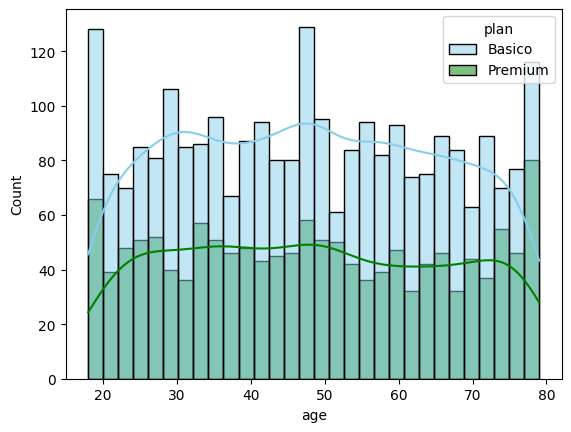

In [49]:
user_profile = users.merge(usage_agg, on='user_id', how='left')

# Histograma para visualizar la edad (age)
sns.histplot(
    data=user_profile, 
    x='age', 
    hue='plan', 
    palette=['skyblue', 'green'], 
    kde=True, 
    bins=30
)
plt.show()


💡Insights: 
- Distribución:
La distribución de la edad de los usuarios es relativamente uniforme a lo largo del rango etario (desde los 20 hasta los 80 años), presentando algunos picos notables alrededor de los 20, 48 y 78 años. En cuanto a los planes, ambos segmentos (Básico y Premium) muestran un comportamiento etario muy similar, sin diferencias estructurales significativas entre ellos.

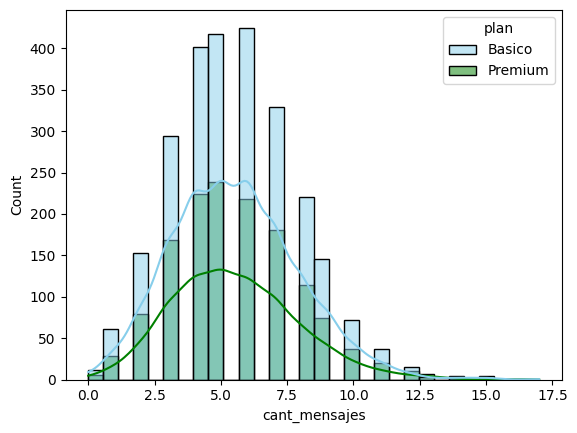

In [51]:

# Histograma para visualizar la cant_mensajes

sns.histplot(
    data=user_profile, 
    x='cant_mensajes', 
    hue='plan', 
    palette=['skyblue', 'green'], 
    kde=True, 
    bins=30
)
plt.show()


💡Insights: 
Distribución: La distribución de la cantidad de mensajes (cant_mensajes) presenta una forma unimodal, con una tendencia simétrica o en forma de campana, concentrándose la mayor frecuencia de usuarios alrededor de los 5 mensajes.
Relación con el plan: Los usuarios de ambos planes (Básico y Premium) muestran un comportamiento de mensajería muy similar, sin diferencias notables en la forma de sus distribuciones, siendo el plan Básico el que presenta mayores frecuencias absolutas en todos los intervalos debido a su mayor proporción en la base de datos.

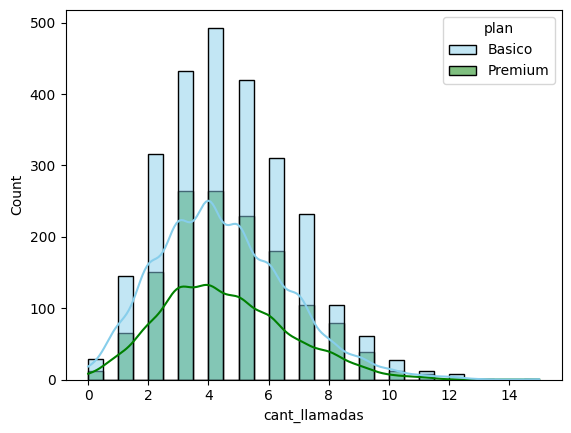

In [52]:
# Histograma para visualizar la cant_llamadas
sns.histplot(
    data=user_profile, 
    x='cant_llamadas', 
    hue='plan', 
    palette=['skyblue', 'green'], 
    kde=True, 
    bins=30
)
plt.show()

💡Insights: 
Distribución: La distribución de la cantidad de llamadas (cant_llamadas) tiene una forma unimodal con una ligera tendencia hacia la derecha, concentrándose la mayor frecuencia de usuarios entre las 4 y 5 llamadas.
Relación con el plan: Ambos tipos de planes (Básico y Premium) presentan un comportamiento muy similar en cuanto a la frecuencia de llamadas, observándose proporciones constantes entre ambos grupos a lo largo de los diferentes valores.

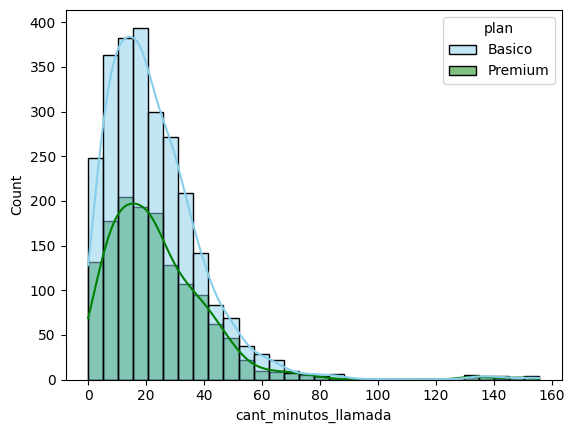

In [53]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(
    data=user_profile, 
    x='cant_minutos_llamada', 
    hue='plan', 
    palette=['skyblue', 'green'], 
    kde=True, 
    bins=30
)
plt.show()


💡Insights: 
- Distribución: La distribución de los minutos totales de llamada (cant_minutos_llamada) muestra un claro sesgo hacia la derecha (asimetría positiva), donde la gran mayoría de los usuarios concentran su consumo en valores bajos, entre los 10 y 30 minutos, con una cola larga hacia los valores más altos.
- Relación con el plan: Ambos planes (Básico y Premium) siguen un patrón de distribución muy similar, manteniendo el plan Básico proporciones superiores en todos los intervalos debido al tamaño de su muestra, sin que se observen diferencias estructurales drásticas en el comportamiento de llamadas.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

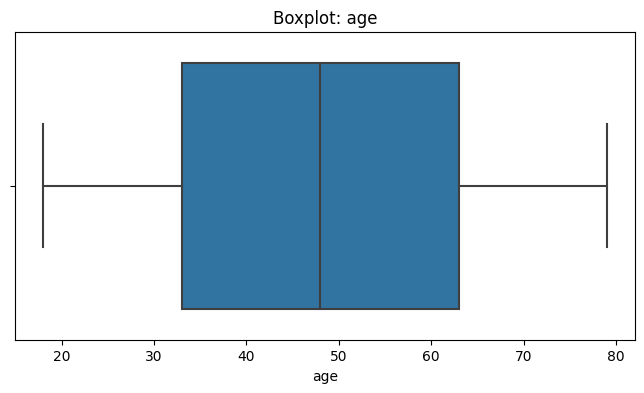

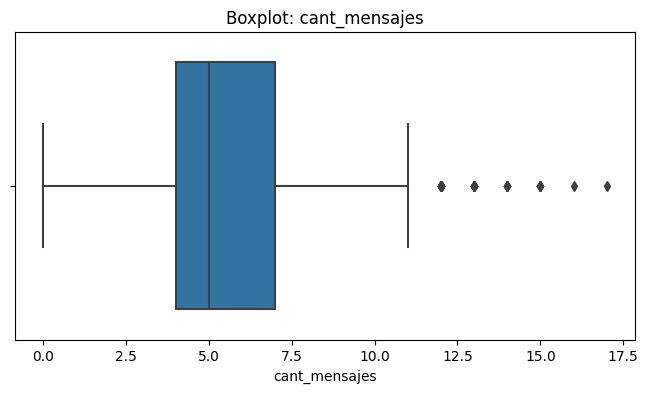

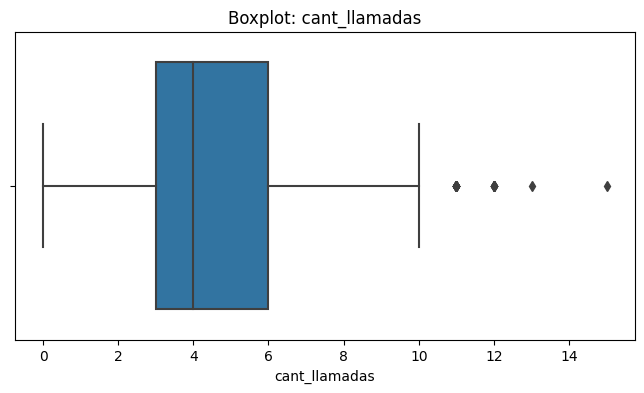

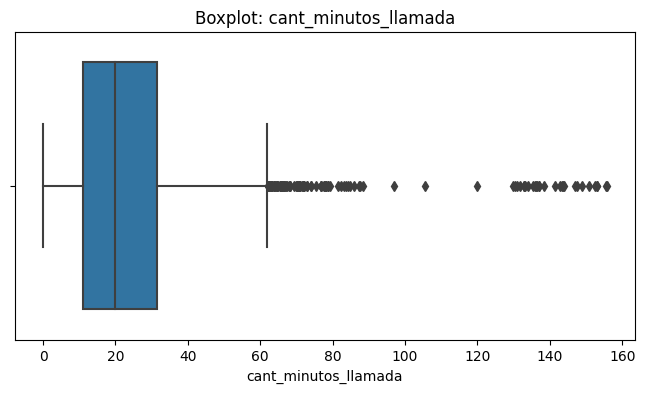

In [54]:

# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=user_profile, x=col)
    plt.title(f'Boxplot: {col}')
    plt.show()


💡Insights: 
- Age: ...(presenta o no outliers): No presenta outliers; los valores se encuentran completamente dentro de los límites de los bigotes (desde los ~18 hasta los 80 años)
- cant_mensajes: cant_mensajes: Sí presenta valores atípicos (outliers) en el límite superior, representados por puntos aislados a partir de aproximadamente 12 mensajes.
- cant_llamadas: Sí presenta outliers en el límite superior, visibles como puntos individuales que superan las 11 llamadas.
- cant_minutos_llamada: Sí presenta una cantidad considerable de outliers en el límite superior, los cuales se extienden de forma marcada desde los 95 minutos hasta cerca de los 160 minutos.

In [58]:



# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    print(f"Variable: {col} -> Límite superior: {limite_superior}")




Variable: cant_mensajes -> Límite superior: 11.5
Variable: cant_llamadas -> Límite superior: 10.5
Variable: cant_minutos_llamada -> Límite superior: 61.8575


In [59]:

# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()


,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
Aunque existen valores por encima del límite superior (11.5) llegando hasta un máximo de 17.0, estos representan un comportamiento real de usuarios con alta actividad de mensajería (power users). No son errores de captura, por lo que eliminarlos sesgaría el análisis del uso real
- cant_llamadas: mantener o no outliers, porqué?
  Los valores que superan el límite superior (10.5) hasta alcanzar un máximo de 15.0 corresponden a clientes con una frecuencia de llamadas legítima y natural dentro de la red, aportando información valiosa sobre el comportamiento de los usuarios más activos.
- cant_minutos_llamada: mantener o no outliers, porqué?
A pesar de que la cola se extiende significativamente más allá del límite superior (61.85) hasta un máximo de 155.69 minutos, estos datos reflejan a clientes reales de alto consumo. Eliminarlos afectaría la evaluación del rendimiento general y la comparación entre los distintos planes de telefonía.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [61]:

# Crear columna grupo_uso
import numpy as np

condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]

resultados = ['Bajo uso', 'Uso medio']

user_profile['grupo_uso'] = np.select(condiciones, resultados, default='Alto uso')


In [62]:

# verificar cambios
user_profile.head()


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_minutos_llamada,total_length,cant_mensajes,cant_llamadas,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,23.70,258.0,7.0,3.0,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,33.18,226.0,5.0,10.0,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,10.74,225.0,5.0,2.0,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,8.99,530.0,11.0,3.0,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,8.01,229.0,4.0,3.0,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [63]:
# Crear columna grupo_edad
import numpy as np

condiciones_edad = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]

resultados_edad = ['Joven', 'Adulto']

user_profile['grupo_edad'] = np.select(condiciones_edad, resultados_edad, default='Adulto Mayor')

In [64]:

# verificar cambios
user_profile.head()


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_minutos_llamada,total_length,cant_mensajes,cant_llamadas,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,23.70,258.0,7.0,3.0,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,33.18,226.0,5.0,10.0,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,10.74,225.0,5.0,2.0,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,8.99,530.0,11.0,3.0,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,8.01,229.0,4.0,3.0,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

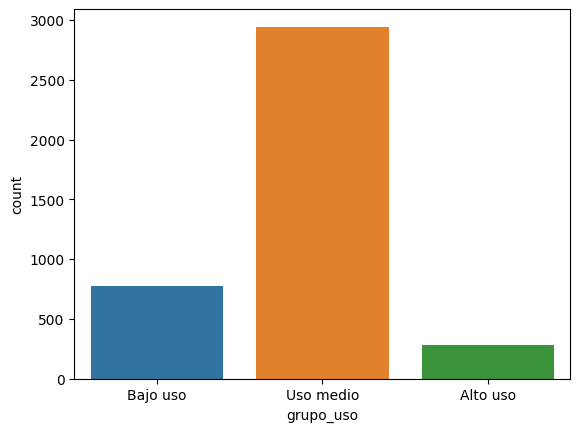

In [65]:

# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'])

plt.show()


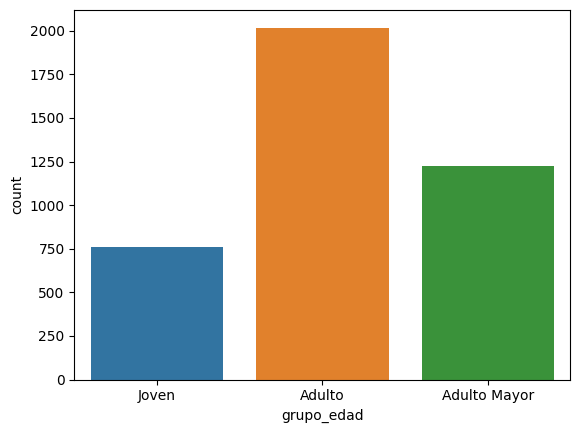

In [66]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'])

plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

- Valores nulos y faltantes: Se identificaron registros con datos vacíos o nulos en columnas clave como el apellido (last_name), ciudad (city) y la fecha de cancelación (churn_date), donde esta última presentaba una alta proporción de nulos al tratarse de clientes activos que continúan en la compañía.

- Inconsistencias de formato y nulos en el plan: Hubo presencia inicial de celdas vacías (<NA>) y variaciones en campos de texto, requiriendo validaciones de tipo de datos (como el manejo de age y métricas de consumo) para asegurar la integridad de la segmentación.



🔍 **Segmentos por Edad**
Se identificaron tres grupos etarios clave:

- Grupo Joven (age < 30): Representa un sector dinámico pero menor en volumen (aproximadamente 750 usuarios), enfocado en la adopción digital y consumo rápido.

- Grupo Adulto (30 \le age < 60): Es el segmento predominante y de mayor peso en la base de datos (superando los 2,000 usuarios), constituyendo el núcleo principal de la masa de clientes de ConnectaTel.

- Grupo Adulto Mayor (age \ge 60): Representa un segmento importante (más de 1,200 usuarios) con patrones de consumo más tradicionales y estables.


📊 **Segmentos por Nivel de Uso**
- Bajo uso: Usuarios con menor interacción en llamadas y mensajes (< 5 en ambas métricas), que probablemente corresponden a líneas secundarias o clientes con baja retención.

- Uso medio: El grupo intermedio que concentra el comportamiento estándar de la base de clientes.

- Alto uso: Clientes con una actividad intensa que superan los umbrales habituales de consumo.

  
Esto sugiere que la base de clientes de ConnectaTel está altamente polarizada en el segmento de adultos y muestra patrones de consumo bien diferenciados, donde un sector minoritario concentra una actividad muy intensa, mientras la mayoría se mantiene en un uso moderado.

💡 **Recomendaciones**

- Valoración de segmentos clave: El segmento Adulto debe considerarse el más valioso en términos de volumen y estabilidad de ingresos, mientras que los usuarios de Alto uso son estratégicos por su intensidad de interacción y su potencial para elevar el ARPU (Ingreso Promedio por Usuario).

- Gestión de patrones de uso extremo (Outliers): Mediante el método IQR, se detectaron power users en llamadas, mensajes y minutos que superan los límites teóricos habituales. Dado que esto implica la existencia de clientes con necesidades muy elevadas que podrían frustrarse si la oferta actual no se adapta a su consumo real, se recomienda diseñar planes especializados (como un esquema "Ilimitado" o "Premium") para retenerlos y evitar su fuga a la competencia.

- Diseño de planes personalizados: Crear paquetes específicos orientados al segmento Adulto que combinen llamadas y datos de forma atractiva, así como tarifas preferenciales o de fidelización para los Adultos Mayores.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`